# Run 내부 온도 변화

같은 제품의 연속 생산 구간에서 시간이 지날수록 금형·배럴·호퍼 온도가 상승하는지 확인한다. 기존 03 노트북과 동일한 원본 연결·샷 통합·품질 필터·run 추정 기준을 사용한다. 초반 상승과 장시간 변화는 구분한다. run은 실제 설정 로그가 없는 후보 구간이며, 라벨 없는 샷을 정상으로 취급하지 않는다.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, mannwhitneyu
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
TABLES = ROOT / 'reports' / 'tables'
FIGURES = ROOT / 'reports' / 'figures'
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': ['Malgun Gothic', 'DejaVu Sans'], 'axes.unicode_minus': False, 'figure.dpi': 120})
raw = pd.read_csv(ROOT / 'data/original/moldset_labeled.csv')
raw['TimeStamp'] = pd.to_datetime(raw['TimeStamp'])
raw['product'] = raw['PART_NAME'].str.extract(r'^(CN7|RG3)', expand=False)
raw['cavity'] = raw['PART_NAME'].str.extract(r'(LH|RH)\s*$', expand=False)
raw['Reason'] = raw['Reason'].fillna('정상')
features = pd.read_csv(ROOT / 'data/moldset_labeled_cn7.csv', nrows=0).columns.drop(['Unnamed: 0', 'PassOrFail']).tolist()
raw['in_competition'] = False
mapping_checks = []
for product in ['CN7', 'RG3']:
    comp = pd.read_csv(ROOT / f'data/moldset_labeled_{product.lower()}.csv')
    candidate = raw.reset_index().set_index('Unnamed: 0')
    idx = comp['Unnamed: 0'].astype(int)
    aligned = candidate.loc[idx].reset_index(drop=True)
    assert aligned['product'].eq(product).all()
    assert np.array_equal(aligned['PassOrFail'].to_numpy(), comp['PassOrFail'].to_numpy())
    for f in features:
        x, y = aligned[f].to_numpy(float), comp[f].to_numpy(float)
        if np.ptp(x) < 1e-8:
            assert np.ptp(y) < 1e-8
            error = 0.
        else:
            coef = np.polyfit(x, y, 1)
            error = float(np.max(np.abs(np.polyval(coef, x)-y)))
            assert error < 1e-6, (product, f, error)
        mapping_checks.append({'product': product, 'feature': f, 'max_affine_error': error})
    raw.loc[aligned['index'].to_numpy(), 'in_competition'] = True
pd.DataFrame(mapping_checks).to_csv(TABLES / 'run_mapping_checks.csv', index=False)
print('Competition rows:', int(raw.in_competition.sum()), 'Original rows:', len(raw))
display(raw.groupby(['product', 'in_competition', 'Reason']).size().rename('rows').reset_index())

Competition rows: 2393 Original rows: 2607


,product,in_competition,Reason,rows
0,CN7,False,정상,204
1,CN7,False,초기허용불량,10
2,CN7,True,가스,13
3,CN7,True,미성형,4
4,CN7,True,정상,1194
5,RG3,True,가스,17
6,RG3,True,미성형,8
7,RG3,True,정상,1157


In [2]:
# 생산 이력: S14의 모든 제품을 남겨 제품 변경도 검출한다.
header = pd.read_csv(ROOT / 'data/original/unlabeled_data.csv', nrows=0).columns
usecols = ['TimeStamp', 'PART_NAME', 'EQUIP_CD'] + features
parts = []
for chunk in pd.read_csv(ROOT / 'data/original/unlabeled_data.csv', usecols=usecols, chunksize=50000):
    parts.append(chunk.loc[chunk['EQUIP_CD'].eq('S14')].copy())
history = pd.concat(parts, ignore_index=True)
history['TimeStamp'] = pd.to_datetime(history['TimeStamp'])
history['product'] = history['PART_NAME'].str.replace(r'[, ]+(LH|RH)\s*$', '', regex=True)
history.loc[history['PART_NAME'].str.startswith('CN7'), 'product'] = 'CN7'
history.loc[history['PART_NAME'].str.startswith('RG3'), 'product'] = 'RG3'
keys = ['EQUIP_CD', 'TimeStamp', 'product']
# Metadata only: never replace absent labels by normal.
labels = raw.groupby(keys, as_index=False).agg(
    PassOrFail=('PassOrFail', 'max'), in_competition=('in_competition', 'max'),
    original_rows=('PassOrFail', 'size'),
    bad_cavities=('cavity', lambda x: ''),
    Reason=('Reason', lambda x: '|'.join(sorted(set(x)-{'정상'})) or '정상'))
cavity_info = raw.loc[raw.PassOrFail.eq(1)].groupby(keys)['cavity'].agg(lambda x: '|'.join(sorted(set(x))))
labels = labels.drop(columns='bad_cavities').merge(cavity_info.rename('bad_cavities'), on=keys, how='left')
labels['bad_cavities'] = labels['bad_cavities'].fillna('')
records = pd.concat([raw[keys + features].assign(source='labeled'),
                     history[keys + features].assign(source='unlabeled')], ignore_index=True)
# Verify paired/repeated sensor values before selecting one record.
sensor_groups = records.groupby(keys)[features]
ranges = sensor_groups.max()-sensor_groups.min()
conflicts = ranges.gt(1e-4).any(axis=1)
conflict_table = ranges.loc[conflicts].reset_index()
conflict_table.to_csv(TABLES / 'run_duplicate_sensor_conflicts.csv', index=False)
print('Shots with conflicting paired/source measurements:', int(conflicts.sum()))
# Label source takes precedence if a source disagreement exists; conflicts are documented.
shots = records.drop_duplicates(keys, keep='first').merge(labels, on=keys, how='left')
shots['in_competition'] = shots['in_competition'].fillna(False).astype(bool)
shots = shots.sort_values(['EQUIP_CD', 'TimeStamp', 'product']).reset_index(drop=True)
ambiguous = shots.groupby(['EQUIP_CD', 'TimeStamp'])['product'].transform('size').gt(1)
assert not shots.loc[ambiguous, 'in_competition'].any(), 'Ambiguous competition shot'
shots.loc[ambiguous, keys].to_csv(TABLES / 'run_ambiguous_product_timestamps.csv', index=False)
print('Excluded ambiguous noncompetition timestamps:', shots.loc[ambiguous, 'TimeStamp'].nunique())
shots = shots.loc[~ambiguous].reset_index(drop=True)
shots = shots.merge(conflict_table[keys].assign(sensor_conflict=True), on=keys, how='left')
shots['sensor_conflict'] = shots['sensor_conflict'].fillna(False).astype(bool)
assert not shots.loc[shots.in_competition, 'sensor_conflict'].any(), 'Competition sensors conflict'
# Keep conflict timestamps for run boundaries, but exclude unreliable values from rolling history.
shots.loc[shots.sensor_conflict, features] = np.nan
shots['prev_gap_sec'] = shots.groupby('EQUIP_CD')['TimeStamp'].diff().dt.total_seconds()
print('Full observed history shots:', len(shots))
print('Competition shots:', shots.in_competition.sum(), 'bad shots:', shots.loc[shots.in_competition, 'PassOrFail'].sum())
display(labels.groupby(['product', 'in_competition']).agg(shots=('PassOrFail','size'), bad_shots=('PassOrFail','sum')))

Shots with conflicting paired/source measurements: 112


Excluded ambiguous noncompetition timestamps: 17


Full observed history shots: 68960
Competition shots: 1197 bad shots: 39.0


shots  bad_shots
product in_competition                  
CN7     False             107          5
        True              606         14
RG3     True              591         25

In [3]:
def assign_runs(frame, gap_minutes):
    out = frame.copy()
    switch = out['product'].ne(out.groupby('EQUIP_CD')['product'].shift())
    start = switch | out['prev_gap_sec'].gt(gap_minutes*60) | out['prev_gap_sec'].isna()
    out['run_number'] = start.cumsum()
    out['run_id'] = out.groupby('run_number')['TimeStamp'].transform('min').dt.strftime('%Y%m%d_%H%M%S') + '_' + out['product']
    out['observed_shot_seq'] = out.groupby('run_id').cumcount()+1
    out['run_elapsed_min'] = (out.TimeStamp-out.groupby('run_id').TimeStamp.transform('min')).dt.total_seconds()/60
    return out

sensitivity, run_tables = [], {}
for threshold in [5, 10, 30, 60]:
    framed = assign_runs(shots, threshold)
    contest = framed.loc[framed.in_competition]
    summary = contest.groupby(['product', 'run_id']).agg(
        labeled_shots=('PassOrFail','size'), bad_shots=('PassOrFail','sum'),
        labeled_start=('TimeStamp','min'), labeled_end=('TimeStamp','max'))
    summary['bad_rate'] = summary.bad_shots/summary.labeled_shots
    run_tables[threshold] = summary.reset_index()
    for p, g in summary.groupby(level=0):
        sensitivity.append({'gap_minutes': threshold, 'product': p, 'runs_with_labels': len(g),
                            'runs_with_defects': int(g.bad_shots.gt(0).sum()),
                            'largest_run_bad_share': g.bad_shots.max()/g.bad_shots.sum(),
                            'total_bad_shots': int(g.bad_shots.sum())})
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(TABLES / 'run_threshold_sensitivity.csv', index=False)
shots = assign_runs(shots, 30)
contest = shots.loc[shots.in_competition].copy()
run_summary = run_tables[30]
full_runs = shots.groupby('run_id').agg(
    run_start=('TimeStamp','min'), run_end=('TimeStamp','max'), observed_shots=('TimeStamp','size'),
    max_internal_gap_sec=('prev_gap_sec', lambda x: x.iloc[1:].max()),
    source_labeled_only_shots=('source', lambda x: x.eq('labeled').sum()))
run_summary = run_summary.merge(full_runs, on='run_id', how='left')
run_summary.to_csv(TABLES / 'run_summary.csv', index=False, encoding='utf-8-sig')
display(run_summary)
display(sensitivity)
# Actual label coverage is uneven: denominators are labeled shots only, not all production.
contest[['run_id','TimeStamp','product','PassOrFail','Reason','bad_cavities','observed_shot_seq','run_elapsed_min','prev_gap_sec']].to_csv(
    TABLES / 'run_labeled_shots.csv', index=False, encoding='utf-8-sig')

,product,run_id,labeled_shots,bad_shots,labeled_start,labeled_end,bad_rate,run_start,run_end,observed_shots,max_internal_gap_sec,source_labeled_only_shots
0,CN7,20201016_035120_CN7,606,14.0,2020-10-16 04:57:47,2020-10-20 06:20:14,0.023102,2020-10-16 03:51:20,2020-10-20 06:20:14,8179,121.0,606
1,RG3,20201020_092218_RG3,341,15.0,2020-10-21 00:16:26,2020-10-22 08:09:24,0.043988,2020-10-20 09:22:18,2020-10-22 23:24:42,3575,126.0,341
2,RG3,20201023_010128_RG3,74,4.0,2020-10-23 01:01:28,2020-10-23 02:36:11,0.054054,2020-10-23 01:01:28,2020-10-23 02:36:11,74,1112.0,74
3,RG3,20201023_031215_RG3,176,6.0,2020-10-23 04:41:48,2020-10-23 07:46:03,0.034091,2020-10-23 03:12:15,2020-10-23 07:46:03,263,125.0,176


,gap_minutes,product,runs_with_labels,runs_with_defects,largest_run_bad_share,total_bad_shots
0,5,CN7,1,1,1.0,14
1,5,RG3,4,4,0.6,25
2,10,CN7,1,1,1.0,14
3,10,RG3,4,4,0.6,25
4,30,CN7,1,1,1.0,14
5,30,RG3,3,3,0.6,25
6,60,CN7,1,1,1.0,14
7,60,RG3,2,2,0.6,25


In [4]:
from scipy.stats import spearmanr
temps = [f for f in features if 'Temperature' in f]
# 10-minute medians reduce sensor noise. Zero is flagged as unavailable, not heating.
temp_shots = shots.loc[shots['product'].isin(['CN7','RG3'])].copy()
temp_shots[temps] = temp_shots[temps].where(temp_shots[temps].gt(0))
temp_shots['bin10'] = (temp_shots.run_elapsed_min//10).astype(int)
binned = temp_shots.groupby(['product','run_id','bin10'])[temps].median().reset_index()
binned['elapsed_hr'] = (binned.bin10+.5)/6
binned.to_csv(TABLES/'run_temperature_10min_medians.csv',index=False)
trend_rows=[]
for (p,rid), g in temp_shots.groupby(['product','run_id']):
    duration = g.run_elapsed_min.max()
    if len(g)<30 or duration<60:
        continue
    bins=binned.loc[binned.run_id.eq(rid)]
    for f in temps:
        v=bins[['elapsed_hr',f]].dropna()
        if len(v)<6:
            continue
        x,y=v.elapsed_hr.to_numpy(),v[f].to_numpy()
        slope=np.polyfit(x,y,1)[0]
        rho=float(spearmanr(x,y).statistic) if np.ptp(y)>0 else 0.
        first=g.loc[g.run_elapsed_min.lt(30),f].median()
        last=g.loc[g.run_elapsed_min.ge(duration-30),f].median()
        trend_rows.append({'product':p,'run_id':rid,'feature':f,'shots':len(g),
                           'duration_hours':duration/60,'bins':len(v),
                           'first30_median':first,'last30_median':last,
                           'end_minus_start':last-first,'slope_per_hour':slope,'spearman_time':rho})
trends=pd.DataFrame(trend_rows)
trends.to_csv(TABLES/'run_temperature_trends.csv',index=False)
rows=[]
for (p,f),g in trends.groupby(['product','feature']):
    good=g.dropna(subset=['end_minus_start'])
    rows.append({'product':p,'feature':f,'eligible_runs':len(g),'comparable_runs':len(good),
                 'median_end_minus_start':good.end_minus_start.median(),
                 'rise_at_least_0_5_fraction':good.end_minus_start.ge(.5).mean(),
                 'fall_at_least_0_5_fraction':good.end_minus_start.le(-.5).mean(),
                 'positive_time_correlation_fraction':g.spearman_time.gt(0).mean(),
                 'strong_positive_time_correlation_fraction':g.spearman_time.ge(.7).mean()})
trend_summary=pd.DataFrame(rows)
trend_summary.to_csv(TABLES/'run_temperature_trend_summary.csv',index=False)
display(trend_summary)
focus_ids=run_summary.run_id.tolist()
display(trends.loc[trends.run_id.isin(focus_ids) & trends.feature.isin(['Mold_Temperature_3','Mold_Temperature_4','Hopper_Temperature','Barrel_Temperature_1','Barrel_Temperature_5'])])
# Fixed early stages use elapsed time from observed run start.
focus=temp_shots.loc[temp_shots.run_id.isin(focus_ids)].copy()
focus['stage']=pd.cut(focus.run_elapsed_min,[-.01,10,30,60,120,360,np.inf],
                      labels=['0-10min','10-30min','30-60min','60-120min','120-360min','360min+'])
stages=focus.groupby(['product','run_id','stage'],observed=True)[temps].median().reset_index()
stages.to_csv(TABLES/'run_temperature_early_stages.csv',index=False)
display(stages[['product','run_id','stage','Mold_Temperature_3','Mold_Temperature_4','Barrel_Temperature_1','Barrel_Temperature_5','Hopper_Temperature']])


,product,feature,eligible_runs,comparable_runs,median_end_minus_start,rise_at_least_0_5_fraction,fall_at_least_0_5_fraction,positive_time_correlation_fraction,strong_positive_time_correlation_fraction
0,CN7,Barrel_Temperature_1,16,13,0.000000,0.000000,0.000000,0.562500,0.000000
1,CN7,Barrel_Temperature_2,26,26,0.000000,0.038462,0.038462,0.615385,0.000000
2,CN7,Barrel_Temperature_3,26,26,0.000000,0.000000,0.000000,0.461538,0.000000
3,CN7,Barrel_Temperature_4,26,26,0.000000,0.038462,0.038462,0.538462,0.038462
4,CN7,Barrel_Temperature_5,26,26,0.000000,0.000000,0.000000,0.538462,0.000000
5,CN7,Barrel_Temperature_6,26,26,0.000000,0.000000,0.000000,0.461538,0.000000
6,CN7,Hopper_Temperature,26,26,0.700000,0.576923,0.192308,0.653846,0.461538
7,CN7,Mold_Temperature_3,16,13,0.350000,0.461538,0.230769,0.625000,0.375000
8,CN7,Mold_Temperature_4,16,13,0.200000,0.384615,0.307692,0.500000,0.375000
9,RG3,Barrel_Temperature_1,22,18,0.150000,0.000000,0.000000,0.636364,0.000000


,product,run_id,feature,shots,duration_hours,bins,first30_median,last30_median,end_minus_start,slope_per_hour,spearman_time
186,CN7,20201016_035120_CN7,Barrel_Temperature_1,8179,98.481667,591,276.300000,276.200012,-0.099988,-0.000541,-0.085755
190,CN7,20201016_035120_CN7,Barrel_Temperature_5,8179,98.481667,591,255.000000,255.000000,0.000000,0.050054,0.258569
192,CN7,20201016_035120_CN7,Hopper_Temperature,8179,98.481667,591,66.900000,69.500000,2.600000,0.065479,0.582758
193,CN7,20201016_035120_CN7,Mold_Temperature_3,8179,98.481667,591,24.800000,23.600000,-1.200000,-0.030455,-0.378615
194,CN7,20201016_035120_CN7,Mold_Temperature_4,8179,98.481667,591,27.500000,24.700001,-2.799999,-0.054084,-0.383337
393,RG3,20201020_092218_RG3,Barrel_Temperature_1,3575,62.040000,373,285.800000,286.200000,0.400000,0.001451,0.140917
397,RG3,20201020_092218_RG3,Barrel_Temperature_5,3575,62.040000,373,265.000000,264.900000,-0.100000,-0.000208,-0.048832
399,RG3,20201020_092218_RG3,Hopper_Temperature,3575,62.040000,373,69.800000,64.100000,-5.700000,-0.031183,-0.467157
400,RG3,20201020_092218_RG3,Mold_Temperature_3,3575,62.040000,373,22.700000,21.100000,-1.600000,-0.004688,-0.070789
401,RG3,20201020_092218_RG3,Mold_Temperature_4,3575,62.040000,373,23.900000,22.500000,-1.400000,-0.000006,0.037958


,product,run_id,stage,Mold_Temperature_3,Mold_Temperature_4,Barrel_Temperature_1,Barrel_Temperature_5,Hopper_Temperature
0,CN7,20201016_035120_CN7,0-10min,24.800000,27.400000,276.300000,255.100000,66.600000
1,CN7,20201016_035120_CN7,10-30min,24.800000,27.500000,276.300000,254.900000,66.900000
2,CN7,20201016_035120_CN7,30-60min,24.900000,27.600000,276.000000,255.200000,66.900000
3,CN7,20201016_035120_CN7,60-120min,25.000000,27.600000,276.200012,255.000000,67.000000
4,CN7,20201016_035120_CN7,120-360min,25.000000,27.500000,276.100006,255.000000,67.100000
5,CN7,20201016_035120_CN7,360min+,24.500000,27.800000,276.200000,254.900000,65.200000
6,RG3,20201020_092218_RG3,0-10min,22.800000,24.000000,285.600000,264.600000,70.250000
7,RG3,20201020_092218_RG3,10-30min,22.700000,23.800000,285.800000,265.100000,69.700000
8,RG3,20201020_092218_RG3,30-60min,22.600000,23.700000,285.700000,264.900000,69.300000
9,RG3,20201020_092218_RG3,60-120min,22.600000,23.750000,286.000000,264.900000,68.500000


In [5]:
# Initial warming by run; available early coverage is reported explicitly.
warming_rows=[]
for (p,rid),g in temp_shots.groupby(['product','run_id']):
    a=g.loc[g.run_elapsed_min.lt(10)]
    b=g.loc[g.run_elapsed_min.ge(50)&g.run_elapsed_min.lt(70)]
    if len(a)<3 or len(b)<3:
        continue
    for f in temps:
        av,bv=a[f].median(),b[f].median()
        if np.isfinite(av) and np.isfinite(bv):
            warming_rows.append({'product':p,'run_id':rid,'feature':f,'initial10_median':av,
                                 'at50_70min_median':bv,'early_rise':bv-av,
                                 'initial_shots':a[f].count(),'late_shots':b[f].count()})
warming=pd.DataFrame(warming_rows)
warming.to_csv(TABLES/'run_temperature_first_hour_warming.csv',index=False)
ws=warming.groupby(['product','feature']).agg(
    runs=('early_rise','size'),median_first_hour_rise=('early_rise','median'),
    fraction_rise_ge_1=('early_rise',lambda x:x.ge(1).mean()),
    fraction_fall_le_minus_1=('early_rise',lambda x:x.le(-1).mean())).reset_index()
ws.to_csv(TABLES/'run_temperature_first_hour_summary.csv',index=False)
display(ws)
display(warming.loc[warming.run_id.isin(focus_ids) & warming.feature.isin(['Mold_Temperature_3','Mold_Temperature_4','Hopper_Temperature'])])
# Inspect settings/time-series changes rather than infer continuous heating from a slope.
daily=focus.assign(date=focus.TimeStamp.dt.date).groupby(['product','run_id','date'])[
    temps+['Injection_Time','Filling_Time','Cycle_Time','Plasticizing_Position']].median().reset_index()
daily.to_csv(TABLES/'run_temperature_daily_medians.csv',index=False)
display(daily[['product','run_id','date','Mold_Temperature_3','Mold_Temperature_4','Cycle_Time','Injection_Time']])


,product,feature,runs,median_first_hour_rise,fraction_rise_ge_1,fraction_fall_le_minus_1
0,CN7,Barrel_Temperature_1,13,0.10,0.000000,0.000000
1,CN7,Barrel_Temperature_2,25,0.00,0.040000,0.000000
2,CN7,Barrel_Temperature_3,25,0.00,0.040000,0.000000
3,CN7,Barrel_Temperature_4,25,0.00,0.040000,0.000000
4,CN7,Barrel_Temperature_5,25,0.10,0.000000,0.000000
5,CN7,Barrel_Temperature_6,25,0.00,0.000000,0.040000
6,CN7,Hopper_Temperature,25,0.10,0.240000,0.040000
7,CN7,Mold_Temperature_3,13,0.60,0.384615,0.000000
8,CN7,Mold_Temperature_4,13,0.05,0.153846,0.076923
9,RG3,Barrel_Temperature_1,17,0.10,0.000000,0.000000


,product,run_id,feature,initial10_median,at50_70min_median,early_rise,initial_shots,late_shots
177,CN7,20201016_035120_CN7,Hopper_Temperature,66.600000,67.000000,0.400000,11,20
178,CN7,20201016_035120_CN7,Mold_Temperature_3,24.800000,24.900000,0.100000,11,20
179,CN7,20201016_035120_CN7,Mold_Temperature_4,27.400000,27.600000,0.200000,11,20
345,RG3,20201020_092218_RG3,Hopper_Temperature,70.250000,68.900000,-1.350000,10,19
346,RG3,20201020_092218_RG3,Mold_Temperature_3,22.800000,22.600000,-0.200000,10,19
347,RG3,20201020_092218_RG3,Mold_Temperature_4,24.000000,23.700000,-0.300000,10,19
354,RG3,20201023_010128_RG3,Hopper_Temperature,63.750000,63.799999,0.049999,10,19
355,RG3,20201023_010128_RG3,Mold_Temperature_3,21.299999,21.799999,0.500000,10,19
356,RG3,20201023_010128_RG3,Mold_Temperature_4,22.650001,23.200001,0.550000,10,19
363,RG3,20201023_031215_RG3,Hopper_Temperature,64.300000,64.600000,0.300000,10,19


,product,run_id,date,Mold_Temperature_3,Mold_Temperature_4,Cycle_Time,Injection_Time
0,CN7,20201016_035120_CN7,2020-10-16,24.400000,27.300000,59.560000,9.59
1,CN7,20201016_035120_CN7,2020-10-17,25.100000,28.700000,36.200000,6.00
2,CN7,20201016_035120_CN7,2020-10-18,25.100000,28.800000,59.520000,9.57
3,CN7,20201016_035120_CN7,2020-10-19,21.600000,22.700000,59.520000,9.55
4,CN7,20201016_035120_CN7,2020-10-20,23.100000,24.200001,59.480000,9.54
5,RG3,20201020_092218_RG3,2020-10-20,21.200000,22.100000,61.780000,1.06
6,RG3,20201020_092218_RG3,2020-10-21,22.000000,23.000000,61.780000,1.06
7,RG3,20201020_092218_RG3,2020-10-22,21.500000,22.800000,61.780000,1.06
8,RG3,20201023_010128_RG3,2020-10-23,21.700001,23.200001,61.779999,1.06
9,RG3,20201023_031215_RG3,2020-10-23,23.299999,24.700001,61.779999,1.06


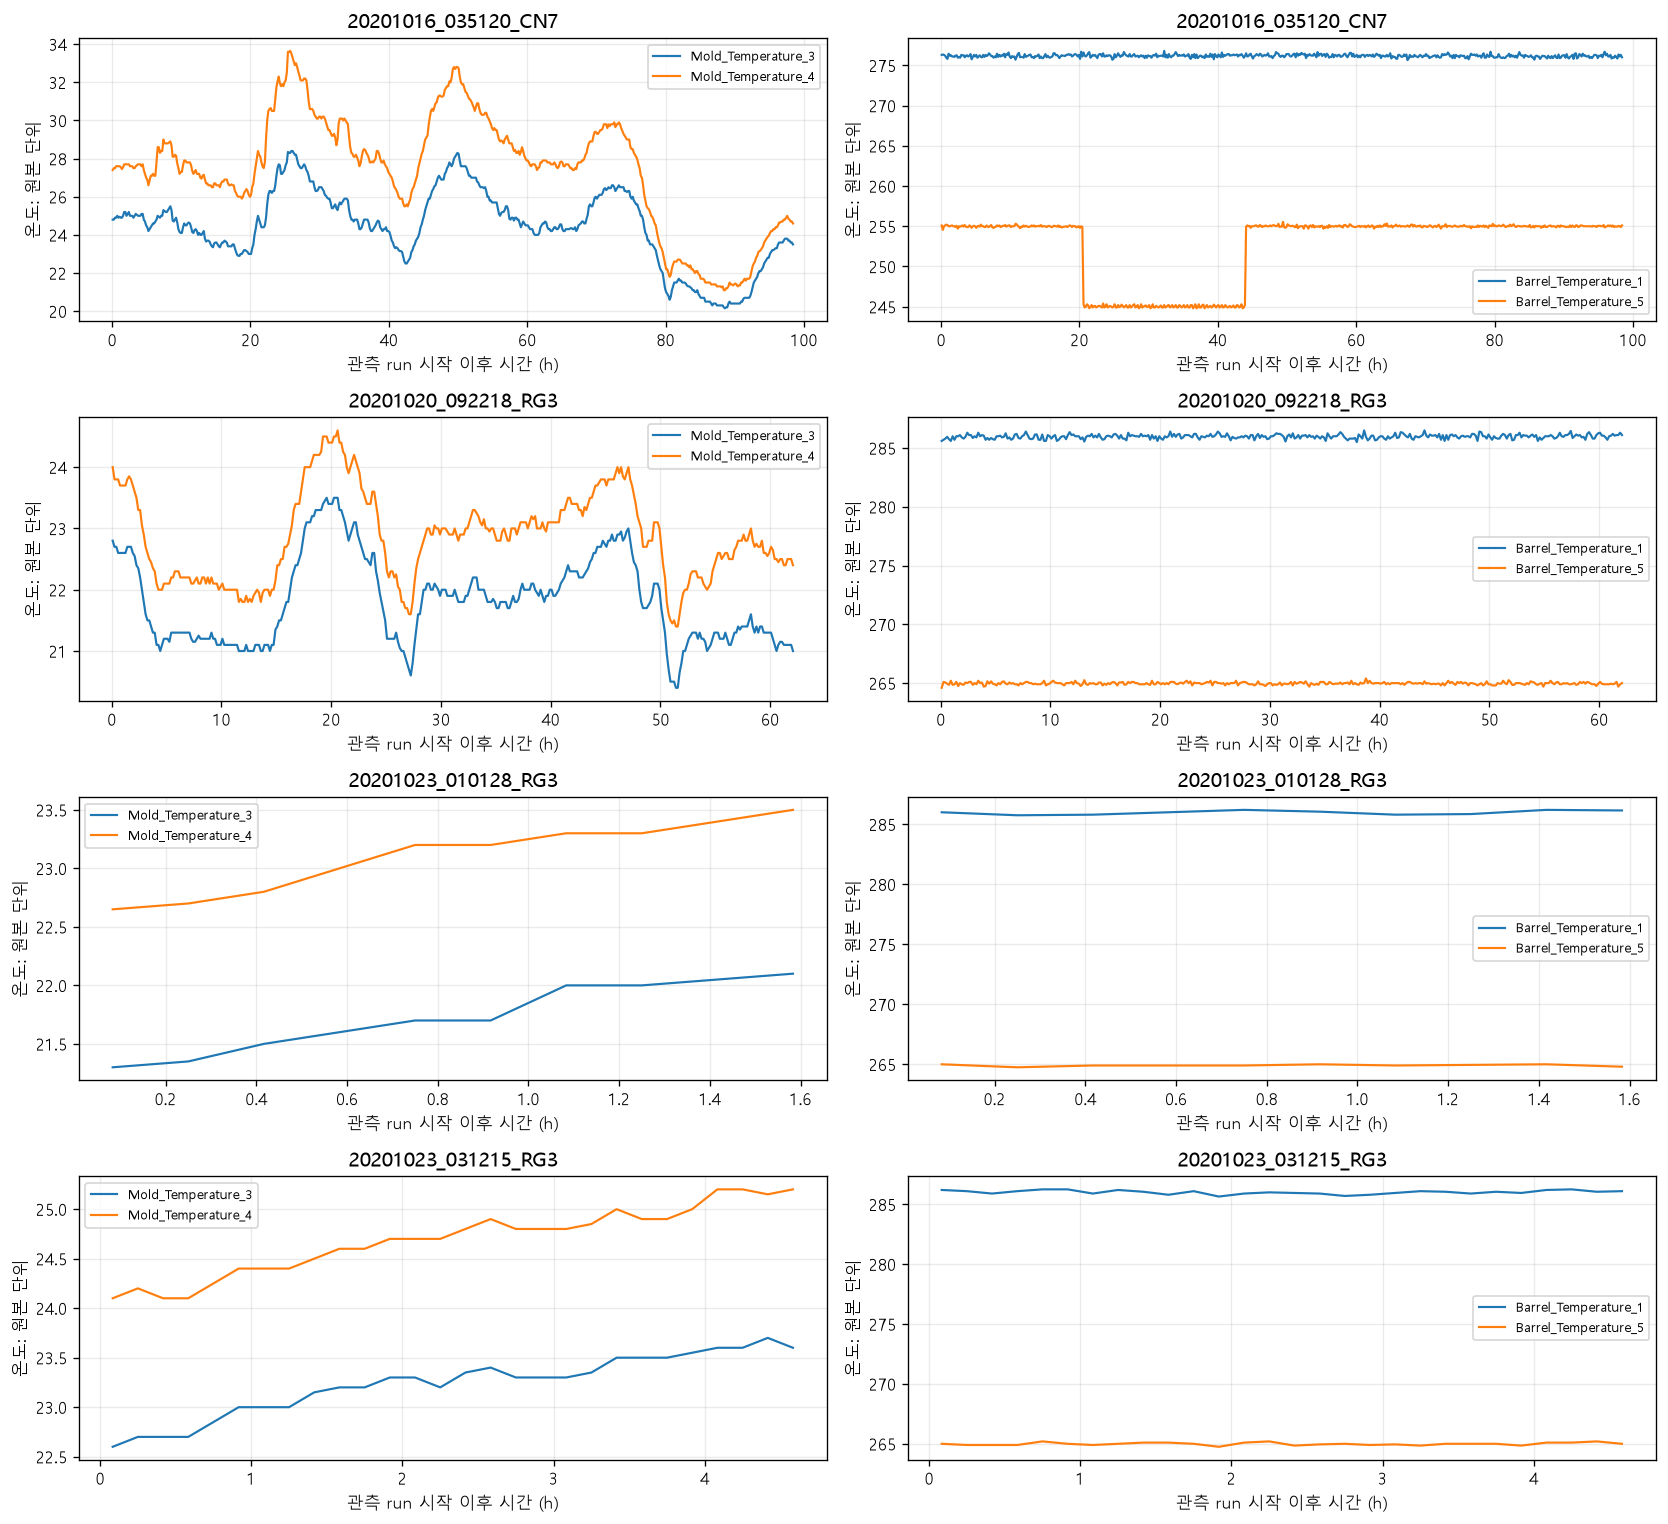

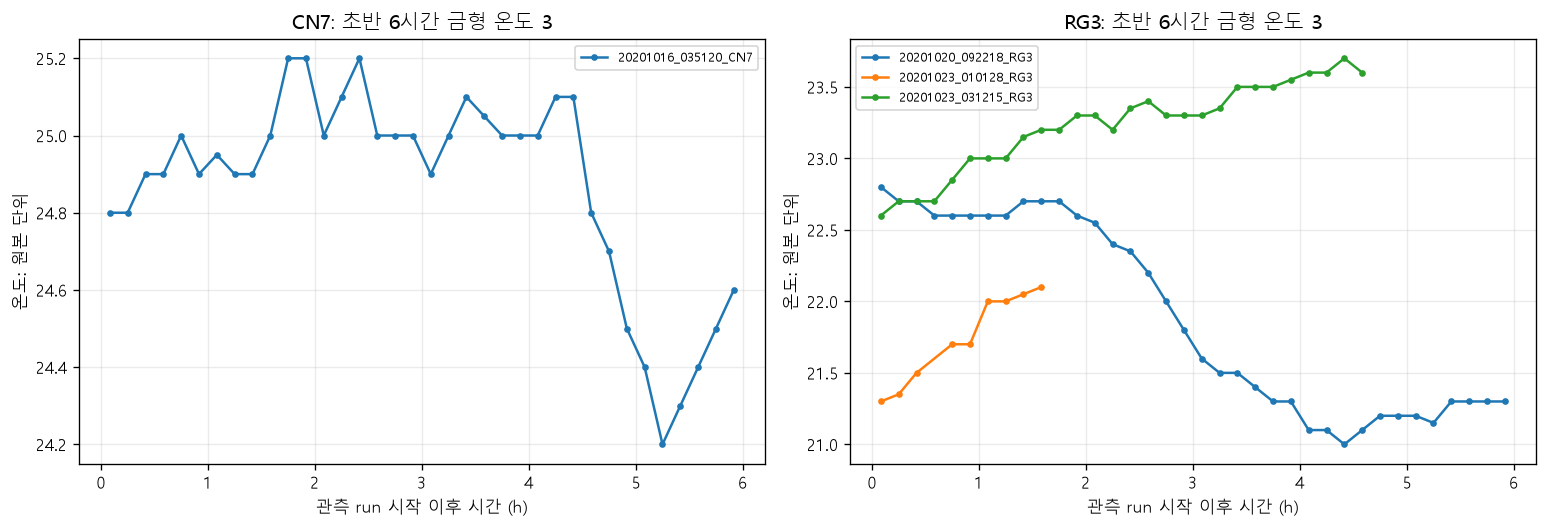

Verified run identity, temperature trend uniqueness, competition shot coverage.


In [6]:
fig,axes=plt.subplots(len(focus_ids),2,figsize=(14,3.2*len(focus_ids)),squeeze=False)
for i,rid in enumerate(focus_ids):
    g=binned.loc[binned.run_id.eq(rid)]
    for ax,fs in [(axes[i,0],['Mold_Temperature_3','Mold_Temperature_4']),
                  (axes[i,1],['Barrel_Temperature_1','Barrel_Temperature_5'])]:
        for f in fs:
            ax.plot(g.elapsed_hr,g[f],label=f,linewidth=1.3)
        ax.set_title(rid)
        ax.set_xlabel('관측 run 시작 이후 시간 (h)')
        ax.set_ylabel('온도: 원본 단위')
        ax.legend(fontsize=8)
        ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(FIGURES/'run_temperature_full_trends.png',bbox_inches='tight')
plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,p in zip(axes,['CN7','RG3']):
    for rid in run_summary.loc[run_summary['product'].eq(p),'run_id']:
        g=binned.loc[binned.run_id.eq(rid)&binned.elapsed_hr.le(6)]
        ax.plot(g.elapsed_hr,g.Mold_Temperature_3,marker='.',label=rid)
    ax.set_title(f'{p}: 초반 6시간 금형 온도 3')
    ax.set_xlabel('관측 run 시작 이후 시간 (h)')
    ax.set_ylabel('온도: 원본 단위');ax.grid(alpha=.25);ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES/'run_temperature_first6hours.png',bbox_inches='tight')
plt.show()
assert not trends.duplicated(['run_id','feature']).any()
assert set(focus_ids).issubset(set(temp_shots.run_id))
assert focus.in_competition.sum()==1197
print('Verified run identity, temperature trend uniqueness, competition shot coverage.')
